In [171]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

In [172]:
# Set the path to the file you'd like to load
file_path = "traffic_flow_sensors.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "olaflundstrom/nordcauc-urban-mobility-intelligence",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)
df.shape
#df["congestion_level"] = df["congestion_level"].map({"free_flow": 0, "light": 1, "moderate": 2, "heavy": 3})


/var/folders/6w/mz34hvxj7514lftxq80xstp80000gn/T/ipykernel_29587/3082049629.py:5: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


(200000, 30)

**Målet**: trafiken 60 minuter fram

**Problem**: Vi vill förutsäga trafikklassen (free_flow, light, moderate, heavy) 60 minuter framåt, utifrån vad vi vet nu.

**Hur**: För varje mätning hämtar vi trafikklassen från samma sensors nästa mätning (groupby('sensor_id') och shift(-1)), och behåller bara rader där nästa mätning är exakt 60 minuter senare. Kolumnen heter future_congestion_level. Kvar blir 2 270 av 200 000 rader (ca 1 %), eftersom få sensorer har en mätning exakt en timme senare.


In [173]:
df['future_congestion_level'] = df.groupby('sensor_id')['congestion_level'].shift(-1)
df['next_timestamp'] = df.groupby('sensor_id')['timestamp'].shift(-1)
df['duration_to_next'] = pd.to_datetime(df['next_timestamp']) - pd.to_datetime(df['timestamp'])

df = df[df['duration_to_next'].dt.total_seconds() / 60 == 60]


In [174]:
len(df)

2270

In [175]:
df.head()

,sensor_id,city,country,district,timestamp,date,hour,day_of_week,is_weekend,is_public_holiday,...,precipitation_mm,weather_condition,incident_type,ai_predicted_volume,ai_predicted_congestion,ai_model_version,data_quality_flag,future_congestion_level,next_timestamp,duration_to_next
162,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-05-28 20:45:00,2023-05-28,20,Sunday,True,False,...,0.5,light_rain,none,124,moderate,NordFlow-GNN,good,moderate,2023-05-28 21:45:00,0 days 01:00:00
311,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2023-09-21 13:45:00,2023-09-21,13,Thursday,False,False,...,2.2,light_rain,none,18,free_flow,NordFlow-GNN,good,free_flow,2023-09-21 14:45:00,0 days 01:00:00
419,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-01-10 17:30:00,2024-01-10,17,Wednesday,False,False,...,0.0,sleet,none,211,heavy,NordFlow-GNN,good,heavy,2024-01-10 18:30:00,0 days 01:00:00
505,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-03-22 00:15:00,2024-03-22,0,Friday,False,False,...,0.0,partly_cloudy,none,19,free_flow,NordFlow-GNN,good,free_flow,2024-03-22 01:15:00,0 days 01:00:00
558,STO-NOR-0001,Stockholm,Sweden,Norrmalm,2024-04-29 14:30:00,2024-04-29,14,Monday,False,False,...,2.4,drizzle,none,23,free_flow,NordFlow-GNN,good,free_flow,2024-04-29 15:30:00,0 days 01:00:00


In [176]:
df['future_congestion_level'].value_counts(normalize=True)

future_congestion_level
free_flow    0.473128
moderate     0.182819
light        0.178414
heavy        0.165639
Name: proportion, dtype: float64

In [177]:
df["road_type"].value_counts()

road_type
arterial      584
expressway    556
collector     439
local         301
motorway      219
boulevard     171
Name: count, dtype: int64

In [178]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2270
Columns: 33


In [179]:
df.info()

<class 'pandas.DataFrame'>
Index: 2270 entries, 162 to 199953
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype          
---  ------                   --------------  -----          
 0   sensor_id                2270 non-null   str            
 1   city                     2270 non-null   str            
 2   country                  2270 non-null   str            
 3   district                 2270 non-null   str            
 4   timestamp                2270 non-null   str            
 5   date                     2270 non-null   str            
 6   hour                     2270 non-null   int64          
 7   day_of_week              2270 non-null   str            
 8   is_weekend               2270 non-null   bool           
 9   is_public_holiday        2270 non-null   bool           
 10  season                   2270 non-null   str            
 11  latitude                 2270 non-null   float64        
 12  longitude                2270 no

### Val av kolumner
Datasetet har 30 kolumner. Vi behåller 22 som beskriver trafiksituationen nu (tid på dygnet, vägtyp, trafikmått, väder, incidenter), samt målet future_congestion_level.

Vi tar bort: identifierare och plats (sensor_id, city, country, district, latitude, longitude), exakt tidpunkt (timestamp, date), färdiga AI-prognoser (ai_predicted_volume, ai_predicted_congestion, ai_model_version) och data_quality_flag. Gruppen valde också att inte ta med ev_count_15min (antal elbilar)

Varför: en modell som ska gälla för alla sensorer ska inte lära sig utantill vilken sensor eller stad en rad kommer från, och de färdiga prognoserna är någon annans gissning som skulle dölja vad vår egen modell lär sig.

Nuvarande trafikklass (congestion_level) och hastighet behålls, eftersom vi känner till dem när vi gissar 60 minuter fram.

In [180]:
kolumner = [
    'sensor_id','timestamp','hour', 'day_of_week', 'is_weekend', 'is_public_holiday', 'season',
    'road_type', 'speed_limit_kmh', 'lane_count', 'vehicle_count_15min',
    'avg_speed_kmh', 'congestion_level', 'occupancy_rate', 'truck_count_15min',
    'temperature_c', 'precipitation_mm', 'weather_condition', 'incident_type', 'future_congestion_level', 'next_timestamp', 'duration_to_next'
]

In [181]:
df = df[kolumner].dropna()
df.info()

<class 'pandas.DataFrame'>
Index: 2270 entries, 162 to 199953
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype          
---  ------                   --------------  -----          
 0   sensor_id                2270 non-null   str            
 1   timestamp                2270 non-null   str            
 2   hour                     2270 non-null   int64          
 3   day_of_week              2270 non-null   str            
 4   is_weekend               2270 non-null   bool           
 5   is_public_holiday        2270 non-null   bool           
 6   season                   2270 non-null   str            
 7   road_type                2270 non-null   str            
 8   speed_limit_kmh          2270 non-null   int64          
 9   lane_count               2270 non-null   int64          
 10  vehicle_count_15min      2270 non-null   int64          
 11  avg_speed_kmh            2270 non-null   float64        
 12  congestion_level         2270 no

In [182]:
df.describe()

,hour,speed_limit_kmh,lane_count,vehicle_count_15min,avg_speed_kmh,occupancy_rate,truck_count_15min,temperature_c,precipitation_mm,duration_to_next
count,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270.000000,2270
mean,11.337445,64.581498,2.631718,266.488106,53.467225,0.251278,9.396035,16.279956,0.512159,0 days 01:00:00
std,6.865628,22.445786,0.982912,324.686855,22.881421,0.196372,11.356147,12.456725,1.174506,0 days 00:00:00
min,0.000000,30.000000,1.000000,9.000000,6.300000,0.031000,0.000000,-6.800000,0.000000,0 days 01:00:00
25%,6.000000,50.000000,2.000000,60.000000,37.100000,0.071000,2.000000,6.100000,0.000000,0 days 01:00:00
50%,11.000000,60.000000,2.000000,159.000000,49.750000,0.237000,6.000000,16.150000,0.000000,0 days 01:00:00
75%,17.000000,80.000000,3.000000,317.000000,67.400000,0.379750,12.000000,28.300000,0.500000,0 days 01:00:00
max,23.000000,130.000000,5.000000,2685.000000,131.300000,0.703000,83.000000,39.100000,11.600000,0 days 01:00:00


### Kategoriska variabler
Undersöker vilka kategorier som finns och vilken kategori som är vanligast i varje textkolumn.


In [183]:
df.describe(include="object")

/var/folders/6w/mz34hvxj7514lftxq80xstp80000gn/T/ipykernel_29587/702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,sensor_id,timestamp,day_of_week,season,road_type,congestion_level,weather_condition,incident_type,future_congestion_level,next_timestamp
count,2270,2270,2270,2270,2270,2270,2270,2270,2270,2270
unique,160,2245,7,4,6,4,11,6,4,2245
top,OSL-BJØ-0043,2025-05-27 04:30:00,Wednesday,Summer,arterial,free_flow,clear,none,free_flow,2025-05-27 05:30:00
freq,28,2,362,584,584,1085,637,1968,1074,2


### Missing values
- Saknade värden kan påverka modellernas resultat.

In [184]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0].sort_values(ascending=False)

Series([], dtype: int64)

In [185]:
# Kontrollera dubbla sensorobservationer
duplicates = df.duplicated(subset=["sensor_id", "timestamp"]).sum()

print("Duplicate observations:", duplicates)


Duplicate observations: 0


#### Undersöker hur trafikflödet är fördelat.

Frågor att besvara:
- Är de flesta mätningar låga eller höga?
- Finns det extrema trafikvärden?
- Är fördelningen jämn eller snedfördelad?
Varför är detta viktigt?

Om trafikflödet är kraftigt snedfördelat kan det påverka regressionen. Det kan också hjälpa oss att välja lämpliga gränser för våra trafikklasser

**Fråga**: Hur är antalet fordon (vehicle_count_15min) fördelat?

**Varför**: Vi vill lära känna datan och kontrollera att den ser rimlig ut innan vi tränar en modell.

**Resultat**: De flesta mätningar har få fordon, och några få har mycket högre värden. Fördelningen är alltså skev åt höger. Därför är medianen en bättre bild av ett typiskt värde än medelvärdet, som dras upp av de extrema värdena.

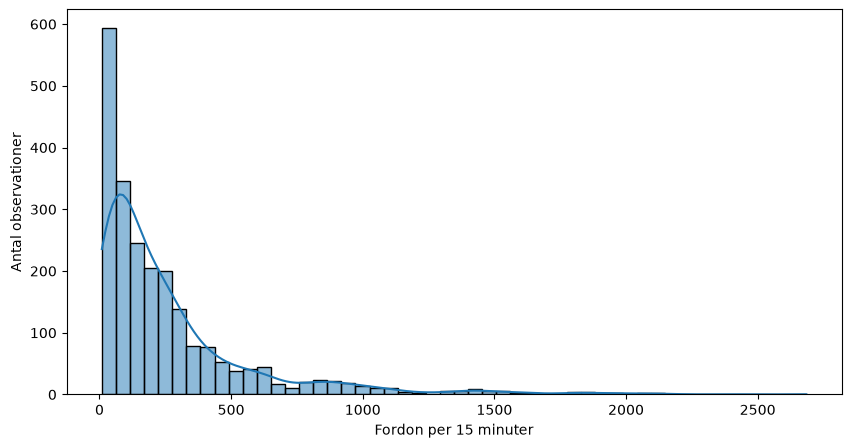

In [186]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df,x="vehicle_count_15min",bins=50,kde=True)

plt.xlabel("Fordon per 15 minuter")
plt.ylabel("Antal observationer")

plt.show()


### undersöker om trafiken varierar under dagen.

Vi förväntar oss eventuellt högre trafik under morgon och eftermiddagsrusning, men det är något vi måste kontrollera i datan.

Varför är detta viktigt?

Om trafiken varierar tydligt beroende på tid på dygnet kan hour vara en viktig feature i våra modeller.

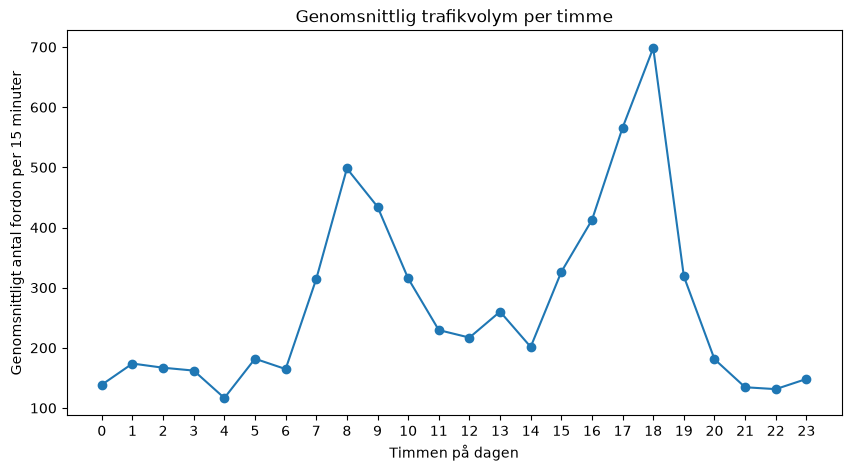

In [187]:
hourly_traffic = df.groupby("hour")["vehicle_count_15min"].mean()
plt.figure(figsize=(10, 5))
hourly_traffic.plot(marker="o")

plt.title("Genomsnittlig trafikvolym per timme")
plt.xlabel("Timmen på dagen")
plt.ylabel("Genomsnittligt antal fordon per 15 minuter")

plt.xticks(range(0, 24))
plt.show()


### undersöker om det finns skillnader mellan vardagar och helger.

- Om vardagar har högre trafik kan det tyda på att arbetspendling påverkar trafikflödet.

- Det kan motivera användningen av day_of_week och is_weekend.undersöker om det finns skillnader mellan vardagar och helger.

- Om vardagar har högre trafik kan det tyda på att arbetspendling påverkar trafikflödet.

- Det kan motivera användningen av day_of_week och is_weekend.

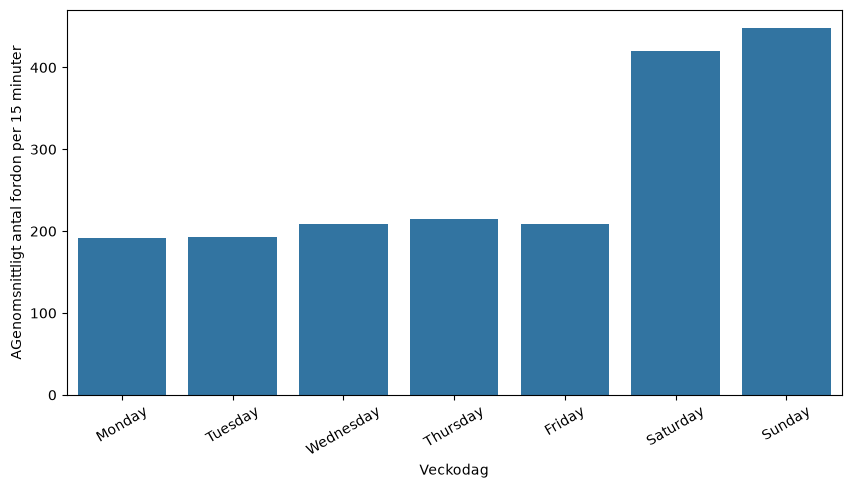

In [188]:
weekday_order = ["Monday", "Tuesday", "Wednesday","Thursday", "Friday", "Saturday", "Sunday"]
weekday_traffic = df.groupby("day_of_week")["vehicle_count_15min"].mean().reindex(weekday_order)

plt.figure(figsize=(10, 5))

sns.barplot(x=weekday_traffic.index,y=weekday_traffic.values)

plt.xlabel("Veckodag")
plt.ylabel("AGenomsnittligt antal fordon per 15 minuter")
plt.xticks(rotation=30)

plt.show()


### Trafik och väder

- Varje punkt representerar en trafikobservation.

- Vi undersöker om det finns något samband mellan temperatur och trafikflöde.

- Om punkterna är väldigt utspridda kanske temperaturen ensam inte kan förklara trafikflödet.

- Punkterna är ganska utspridda, med ett svagt positivt samband. I det här urvalet verkar temperaturen ensam alltså inte förklara trafikvolymen särskilt väl.

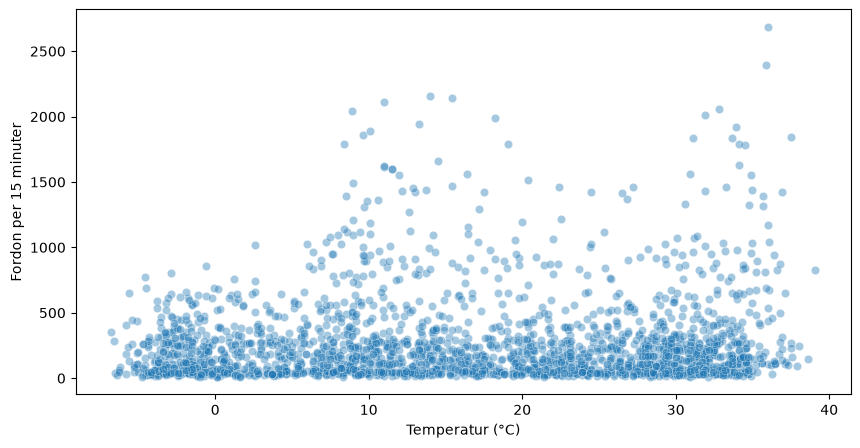

In [189]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df.sample(min(5000, len(df)), random_state=42),x="temperature_c",y="vehicle_count_15min",alpha=0.4)

plt.xlabel("Temperatur (°C)")
plt.ylabel("Fordon per 15 minuter")

plt.show()


### Trafikbelastning per väder
**Fråga**: Påverkar vädret (weather_condition) vilken trafikklass vi får?

**Varför**: Väder är något vi kan känna till i förväg (t.ex. via väderprognos), så det kan användas för att förutsäga framtida trafik. Om fördelningen av trafikklasser skiljer sig mellan väderförhållanden separerar vädret klasserna och är en användbar feature.

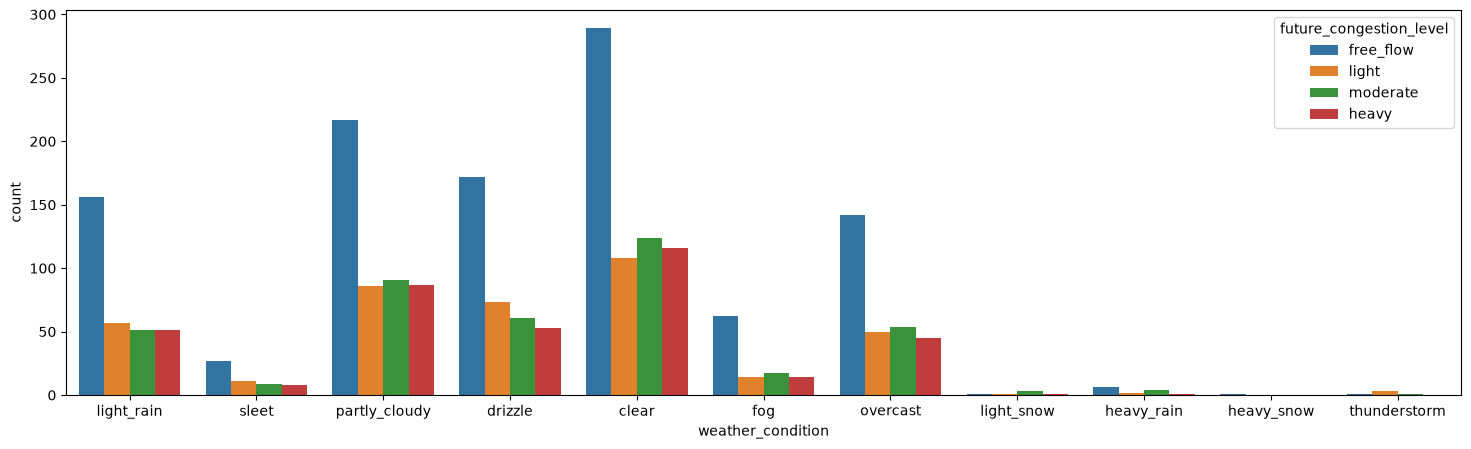

In [190]:
plt.figure(figsize=(18, 5))
sns.countplot(data=df, x='weather_condition', hue='future_congestion_level', hue_order=['free_flow', 'light', 'moderate', 'heavy'])
plt.show()

### Visar antalet förekomster av varje framtida trängselnivå i datasetet.

In [192]:
class_counts = df["future_congestion_level"].value_counts()
print(class_counts)

future_congestion_level
free_flow    1074
moderate      415
light         405
heavy         376
Name: count, dtype: int64


## Visualisera klassfördelningen
### undersöker om klasserna är jämnt fördelade.

- Många observationer med free_flow.
- Färre observationer med heavy
- Om en klass är mycket vanligare än de andra kan modellen bli bra på att förutsäga den vanligaste klassen, men dålig på att identifiera exempelvis kraftiga trafikstockningar.
Detta påverkar senare hur vi utvärderar modellen.

**Fråga**: Är de fyra trafikklasserna (free_flow, light, moderate, heavy) jämnt fördelade, eller är någon klass mycket vanligare?

**Varför**: Om en klass dominerar kan en modell få hög accuracy genom att alltid gissa den klassen. Då behöver vi veta vad en enkel gissning ger för att kunna bedöma om modellen faktiskt lär sig något.

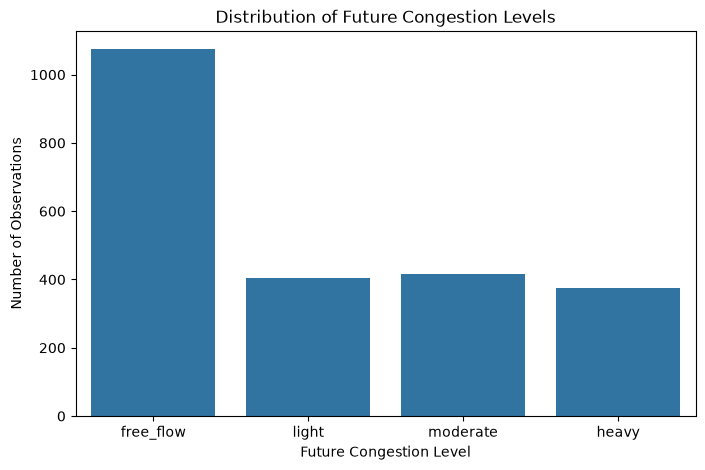

In [193]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df,x="future_congestion_level",order=["free_flow", "light", "moderate", "heavy"])

plt.title("Distribution of Future Congestion Levels")
plt.xlabel("Future Congestion Level")
plt.ylabel("Number of Observations")

plt.show()

### Klassfördelning i procent
- Vi får en tydligare bild av hur stor andel varje trafikklass representerar.
- **Resultat**
  
free_flow är vanligast (47,3 %) och heavy minst (16,6 %).

Att alltid gissa free_flow ger alltså 47,3 % rätt, och det är vår baslinje.

En modell måste slå 47,3 % på testdatan för att visa att den har lärt sig något.

In [194]:
df['future_congestion_level'].value_counts(normalize=True)* 100

future_congestion_level
free_flow    47.312775
moderate     18.281938
light        17.841410
heavy        16.563877
Name: proportion, dtype: float64

### Trafikbelastning per timme

- Är trafiken mer belastad under morgonen?
- Finns det en tydlig eftermiddagsrusning?
- Är trafiken lugnare under natten?
- Vad kan vi dra för slutsats?

Om trafikstockningar förekommer oftare under vissa timmar kan hour vara en användbar variabel för klassificering.

**Fråga**: Varierar trafikklassen 60 minuter fram (future_congestion_level) beroende på tid på dygnet?

**Varför**: Timmen är känd i förväg, så den kan användas för att förutsäga framtida trafik. Om heavy är vanligare vid vissa timmar (t.ex. rusningstid) separerar hour klasserna och är en användbar feature.

**Resultat**: Heavy är vanligast kl. 7-8 och 16-17, en timme före själva rusningstiden, eftersom hour är klockslaget för mätningen men trafikklassen gäller 60 minuter senare.

Light är vanligast strax före och efter topparna (kl. 6, 9, 15 och 18). Free_flow är vanligast nattetid (0-5), mitt på dagen (10-14) och sent på kvällen (19-23).

Klasserna fördelas alltså tydligt olika över dygnet, så hour separerar klasserna väl. Det gör hour till en användbar feature, och eftersom timmen är känd i förväg kan den användas för att förutsäga framtida trafik.


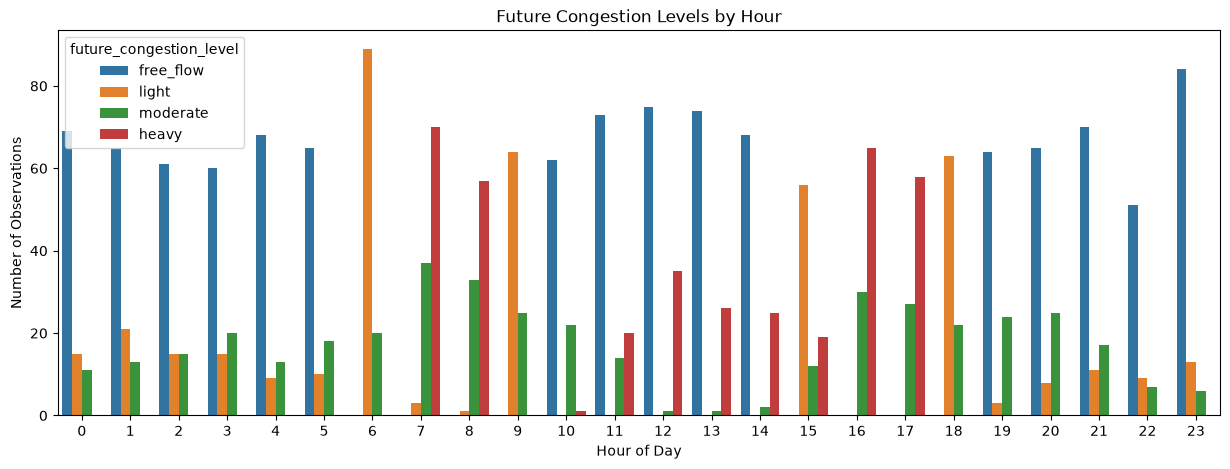

In [195]:
plt.figure(figsize=(15, 5))
sns.countplot(data=df,x="hour", hue="future_congestion_level",hue_order=["free_flow", "light", "moderate", "heavy"])

plt.title("Future Congestion Levels by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Observations")

plt.show()


### Trafikbelastning under en hel vecka
- Undersöker om trafikstockningar är vanligare under arbetsdagar än under helger.
- Det kan hjälpa oss förstå om arbetsrelaterad trafik påverkar congestion.
  
**Resulatet** visar att trängselnivåerna varierar beroende på veckodag, med vissa dagar som tenderar att ha högre trängsel än andra

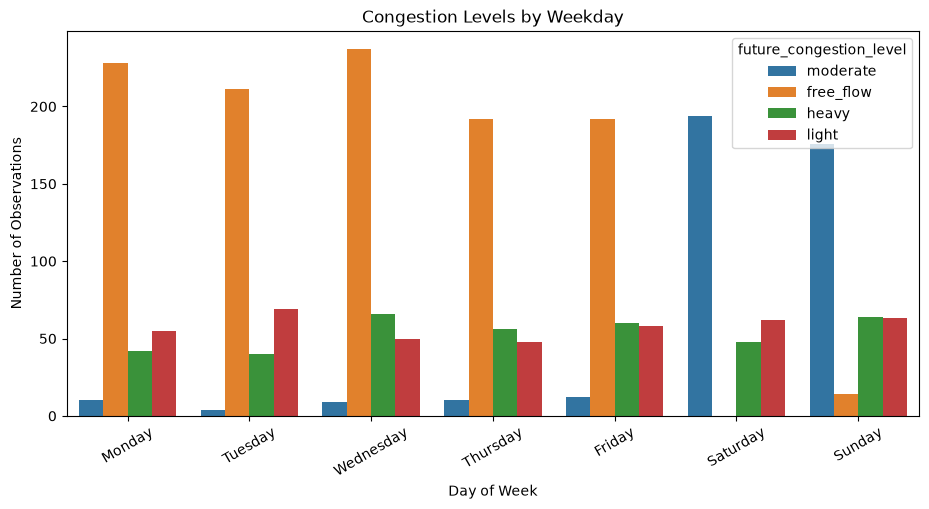

In [196]:
plt.figure(figsize=(11, 5))

sns.countplot(data=df,x="day_of_week",hue="future_congestion_level",order=["Monday", "Tuesday", "Wednesday","Thursday", "Friday", "Saturday", "Sunday"])

plt.title("Congestion Levels by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Number of Observations")
plt.xticks(rotation=30)

plt.show()


### Trafikklass en timme framåt: vardag och helg
Tabellen visar vilken trafikklass sensorn har en timme efter den aktuella mätningen, uppdelat efter om den aktuella mätningen gjordes på en vardag eller helg.

Vardag: Klassen en timme senare är oftast free_flow (64,28 %).
Helg: Klassen en timme senare är oftast moderate (59,58 %).
Det finns alltså en tydlig skillnad i detta urval. Därför kan is_weekend vara en användbar feature. Resultatet visar dock ett samband inte att helgen i sig orsakar skillnaden.

In [197]:
weekend_congestion = pd.crosstab(df["is_weekend"],df["future_congestion_level"],normalize="index") * 100
print(weekend_congestion.round(2))


future_congestion_level  free_flow  heavy  light  moderate
is_weekend                                                
False                        64.28  16.01  16.98      2.73
True                          2.25  18.04  20.13     59.58


In [198]:
#antalet observationer.
pd.crosstab(df["is_weekend"], df["future_congestion_level"])


future_congestion_level,free_flow,heavy,light,moderate
is_weekend,,,,
False,1060,264,280,45
True,14,112,125,370


In [199]:
#Kontrollerar att is_weekend stämmer med datumet. Skillnaden mellan vardag och helg är ovanligt stor, kanske värd att undersöka.

actual_weekend = pd.to_datetime(df["timestamp"]).dt.dayofweek >= 5
(df["is_weekend"] == actual_weekend).value_counts()

/var/folders/6w/mz34hvxj7514lftxq80xstp80000gn/T/ipykernel_29587/4231606598.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  actual_weekend = pd.to_datetime(df["timestamp"]).dt.dayofweek >= 5


True    2270
Name: count, dtype: int64

### Kontrollera att future_congestion_level skapades korrekt och att varje rad verkligen jämförs med rätt framtida mätning.

#### resultat:
betyder att bara 675 av 2 110 rader (cirka 32 %) har samma framtida klass som nästa tidsstämplade mätning för samma sensor. 1 435 rader matchar inte. Om future_congestion_level ska betyda just det, är target-kolumnen troligen skapad på ett annat sätt, till exempel utan gruppering per sensor eller innan raderna sorterades.


In [200]:
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(["sensor_id", "timestamp"]).copy()

df["expected_future_congestion"] = (df.groupby("sensor_id")["congestion_level"].shift(-1))

df["expected_future_timestamp"] = (df.groupby("sensor_id")["timestamp"].shift(-1))

check = df.loc[df["expected_future_congestion"].notna(),
    [
        "sensor_id",
        "timestamp",
        "congestion_level",
        "expected_future_timestamp",
        "expected_future_congestion",
        "future_congestion_level",
    ],
].copy()

check["target_matches"] = check["future_congestion_level"].eq(check["expected_future_congestion"])

check["target_matches"].value_counts()

target_matches
False    1435
True      675
Name: count, dtype: int64

Antalet observationer kan skilja sig mellan vardagar och helger. Genom att använda procent kan vi jämföra fördelningen på ett rättvisare sätt.

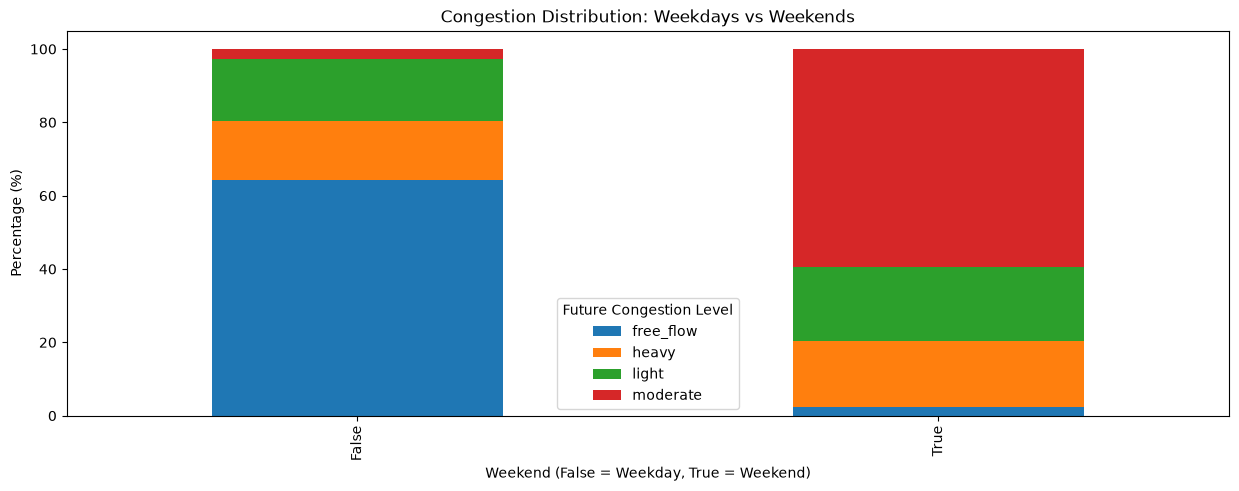

In [201]:
weekend_congestion.plot(kind="bar",stacked=True,figsize=(15, 5))

plt.title("Congestion Distribution: Weekdays vs Weekends")
plt.xlabel("Weekend (False = Weekday, True = Weekend)")
plt.ylabel("Percentage (%)")
plt.legend(title="Future Congestion Level")

plt.show()


### Hastighet och trafikklass en timme senare

Undersöker om den aktuella medelhastigheten (`avg_speed_kmh`)
har ett samband med trafikklassen en timme senare
(`future_congestion_level`).

Boxploten visar medianen och spridningen av hastigheten för varje
framtida trafikklass. Det hjälper oss att se om hastigheten skiljer
sig mellan klasserna.

I vårt urval är den genomsnittliga hastigheten vid startmätningen
cirka 60 km/h när den framtida klassen är `free_flow`, jämfört
med cirka 40 km/h när den är `heavy`.

Det tyder på att hastighet kan vara en användbar feature. Vi kan
använda den om den är känd vid prognostillfället, men vi behöver
testa med en modell om den faktiskt förbättrar förutsägelserna.

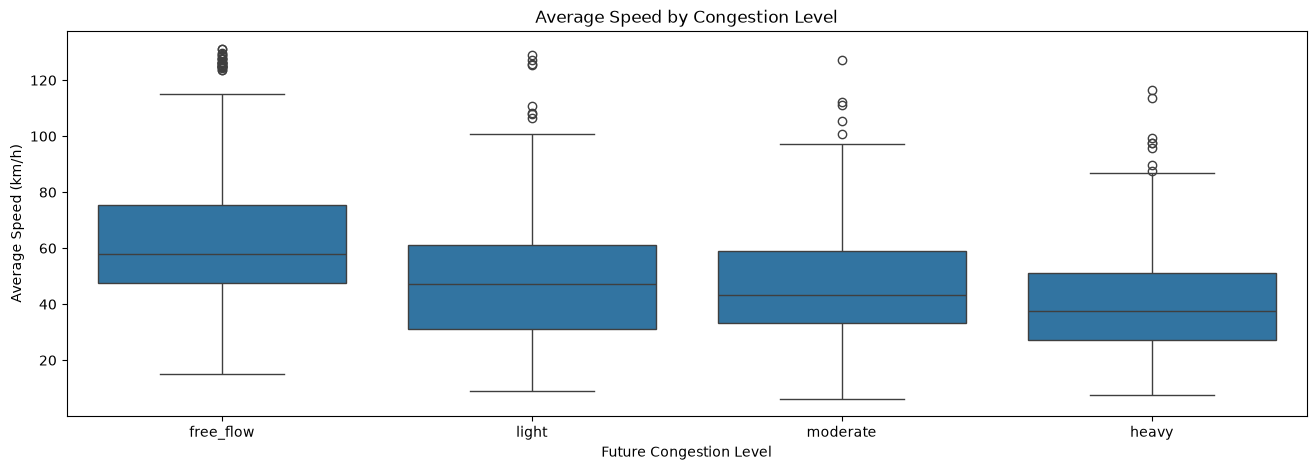

In [202]:
plt.figure(figsize=(16, 5))
sns.boxplot(data=df,x="future_congestion_level",y="avg_speed_kmh",order=["free_flow", "light", "moderate", "heavy"])

plt.title("Average Speed by Congestion Level")
plt.xlabel("Future Congestion Level")
plt.ylabel("Average Speed (km/h)")

plt.show()

### Skapa framtida target
Konvertera tidsstämpeln. 
Ta bort alla rader i upprepade sensor-tidsgrupper innan vi skapar target, eftersom en del av dubblettgrupperna har flera rader med samma tidsstämpel, men olika värden i congestion_level.


In [203]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

duplicate_rows = df.duplicated(
    subset=["sensor_id", "timestamp"],
    keep=False,
)

print("Rader i upprepade sensor-tidsgrupper:", duplicate_rows.sum())

df = df.loc[~duplicate_rows].copy()
df = df.sort_values(["sensor_id", "timestamp"])

Rader i upprepade sensor-tidsgrupper: 0


## Använd senare vid behov
df["congestion_current"] = df["congestion_level"]
df["target_time"] = df.groupby("sensor_id")["timestamp"].shift(-1)
df["y_future"] = df.groupby("sensor_id")["congestion_level"].shift(-1)
df["gap_hours"] = (
    df["target_time"] - df["timestamp"]
).dt.total_seconds() / 3600

samples = df.dropna(subset=["target_time", "y_future"]).copy()
samples.head()

In [204]:
df.groupby('weather_condition')['future_congestion_level'].value_counts(normalize=True)

weather_condition  future_congestion_level
clear              free_flow                  0.453689
                   moderate                   0.194662
                   heavy                      0.182104
                   light                      0.169545
drizzle            free_flow                  0.479109
                   light                      0.203343
                   moderate                   0.169916
                   heavy                      0.147632
fog                free_flow                  0.579439
                   moderate                   0.158879
                   light                      0.130841
                   heavy                      0.130841
heavy_rain         free_flow                  0.461538
                   moderate                   0.307692
                   light                      0.153846
                   heavy                      0.076923
heavy_snow         free_flow                  1.000000
light_rain         fre

**Resultat**: De flesta väder har ungefär samma fördelning som totalen (ca 47 % free_flow). Fog har lite fler free_flow (58 %).

Väder med få rader (heavy_snow, thunderstorm, light_snow) ger extrema procenttal som inte går att lita på. Vädret separerar klasserna svagare än hour och är en möjlig men inte avgörande feature. Vi behåller den och testar i modellen om den hjälper.



In [205]:
df['weather_condition'].value_counts()

weather_condition
clear            637
partly_cloudy    481
drizzle          359
light_rain       315
overcast         291
fog              107
sleet             55
heavy_rain        13
light_snow         6
thunderstorm       5
heavy_snow         1
Name: count, dtype: int64

### Samband mellan siffer-kolumner
**Fråga**: Hur hänger siffer-kolumnerna ihop med varandra?

**Varför**: Kolumner som säger nästan samma sak behövs inte båda två. Vi vill också hitta kolumner som avslöjar svaret, så att vi inte använder dem

**Resultat**: Två par hänger starkt ihop: truck_count_15min och vehicle_count_15min (0,93) samt speed_limit_kmh och avg_speed_kmh (0,82).

Det är logiskt: fler fordon ger fler lastbilar, och vägar med högre hastighetsgräns har högre medelhastighet. Kolumnerna i varje par säger nästan samma sak. Temperatur och nederbörd hänger inte ihop med något (nära 0). Målet är text och syns inte i heatmapen, så det undersöker vi i nästa steg.

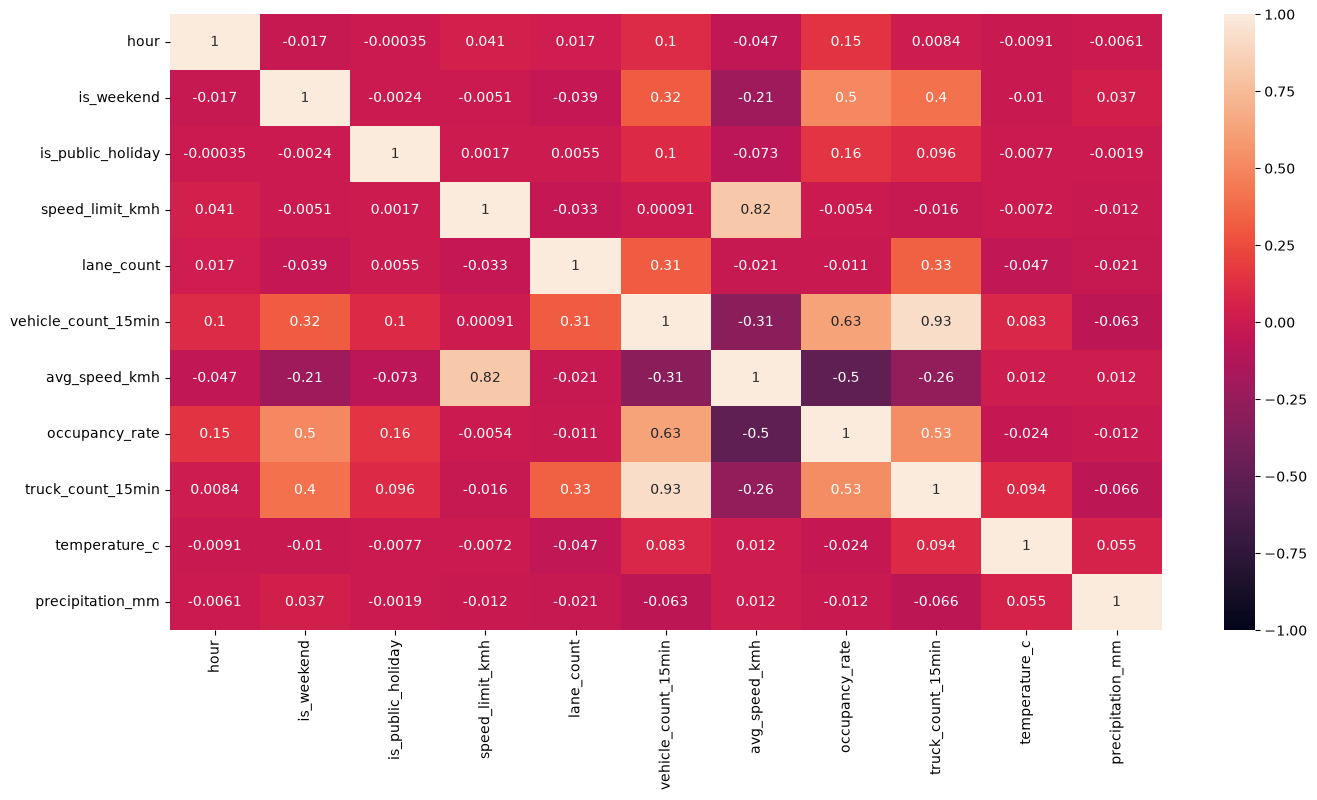

In [206]:
plt.figure(figsize=(16, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, vmin=-1, vmax=1)
plt.show()

# Slutsatser

## Målet och urvalet

Vi undersöker om vi kan förutsäga trafikklassen en timme framåt,
utifrån information från den aktuella mätningen.

Av 200 000 rader återstår 2 270 där nästa registrerade mätning
vid samma sensor är exakt 60 minuter senare. Resultaten gäller
därför detta urval och representerar inte nödvändigtvis all trafik.

## Klassfördelning

Den vanligaste framtida klassen är free_flow (47,3 %), medan heavy
är minst vanlig (16,6 %). Klasserna är alltså inte jämnt fördelade.

En modell som alltid gissar free_flow skulle få 47,3 % rätt i hela
urvalet. För den faktiska baslinjen ska vi träna en DummyClassifier
på träningsdata och utvärdera den på testdata.

## Tid och veckodag

Trafikklassen en timme senare varierar med tid på dygnet.
I urvalet är antalet heavy-observationer särskilt högt när den
aktuella mätningen gjordes kl. 7–8 och 16–17. Därför kan hour
vara en användbar feature.

Jag ser också en tydlig skillnad mellan vardag och helg.
Efter vardagsmätningar är free_flow vanligast en timme senare
(64,28 %). Efter helgmätningar är moderate vanligast (59,58 %).
Jag har kontrollerat att is_weekend stämmer med datumet för alla
2 270 rader. Skillnaden visar ett samband, inte vad som orsakar det.

## Hastighet och trafikvolym

Den aktuella medelhastigheten skiljer sig mellan de framtida
klasserna: cirka 60 km/h när klassen en timme senare är free_flow
och cirka 40 km/h när den är heavy. Hastighet kan därför vara en
användbar feature, förutsatt att den är känd vid prognostillfället.

Antalet lastbilar och det totala antalet fordon har en stark
korrelation (0,93). Även hastighetsgräns och medelhastighet har
en stark korrelation (0,82). Variablerna innehåller alltså delvis
liknande information, men det betyder inte att de är identiska.

## Väder

Fördelningen av framtida trafikklasser är ofta liknande mellan
vädertyperna. Vädret verkar därför inte ensamt skilja klasserna
lika tydligt som tid och hastighet. Vissa vädertyper har mycket
få observationer, så deras resultat är osäkra.

## Nästa steg

Vi kanske behöver testa om de observerade sambanden faktiskt hjälper en
modell att förutsäga framtida trafik. Vi jämför först med en
baseline och utvärderar sedan modeller på data som inte användes
vid träningen. Vi tittar på bland annat macro F1 och confusion
matrix, inte bara accuracy.